## Step 10 - Fairness and bias audit (age groups)

In [1]:
import os
import json
import joblib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    precision_score, recall_score, f1_score, balanced_accuracy_score, average_precision_score
)
from fairlearn.metrics import (
    MetricFrame, count, selection_rate, true_positive_rate, false_positive_rate,
    equalized_odds_difference, demographic_parity_ratio
)
from fairlearn.postprocessing import ThresholdOptimizer

In [2]:
from features import load_data

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 200)
os.makedirs("plots", exist_ok=True)
os.makedirs("results", exist_ok=True)

In [3]:
X_dev, y_dev, X_test, y_test = load_data()
X_train, X_calib, y_train, y_calib = train_test_split(
    X_dev, y_dev, test_size=0.20, stratify=y_dev, random_state=42
)

In [4]:
model = joblib.load("models/final_calibrated_model.pkl")
info = json.load(open("results/final_model_info.json"))
threshold = info["threshold"]
print("Final model:", info["model"], "| calibration:", info["calibration"], "| threshold:", round(threshold, 3))

Final model: lightgbm | calibration: sigmoid (Platt) | threshold: 0.27


In [5]:
def age_group(X):
    return pd.cut(X["age"], bins=[0, 24, 59, 200], labels=["under 25", "25-59", "60+"]).astype(str)


groups_test = age_group(X_test)
groups_calib = age_group(X_calib)

In [6]:
def base_rate(y_true, y_pred):
    return np.mean(y_true)


metrics = {
    "count": count,
    "base_rate": base_rate,
    "selection_rate": selection_rate,
    "TPR (recall)": true_positive_rate,
    "FPR": false_positive_rate,
    "PPV (precision)": precision_score,
}

In [7]:
# ---------------- 1. audit before mitigation ----------------
proba_test = model.predict_proba(X_test)[:, 1]
y_pred_before = (proba_test >= threshold).astype(int)

mf_before = MetricFrame(metrics=metrics, y_true=y_test, y_pred=y_pred_before, sensitive_features=groups_test)
print("\n--- BEFORE MITIGATION (one threshold for everybody), test set ---")
print(mf_before.by_group.round(3))
print("\nOverall:")
print(mf_before.overall.round(3))
print("\nDifference max - min between groups:")
print(mf_before.difference().round(3))


--- BEFORE MITIGATION (one threshold for everybody), test set ---


           count  base_rate  selection_rate  TPR (recall)    FPR  PPV (precision)
age                                                                              
25-59     8554.0      0.106           0.089         0.431  0.048            0.514
60+        337.0      0.332           0.540         0.804  0.409            0.495
under 25   152.0      0.257           0.375         0.769  0.239            0.526

Overall:
count              9043.000
base_rate             0.117
selection_rate        0.111
TPR (recall)          0.483
FPR                   0.061
PPV (precision)       0.511
dtype: float64

Difference max - min between groups:
count              8402.000
base_rate             0.226
selection_rate        0.451
TPR (recall)          0.372
FPR                   0.361
PPV (precision)       0.032
dtype: float64


In [8]:
# ranking quality by group (uses the probabilities, not the decisions)
mf_prauc = MetricFrame(metrics={"pr_auc": average_precision_score}, y_true=y_test,
                       y_pred=proba_test, sensitive_features=groups_test)
print("\nPR-AUC by group:")
print(mf_prauc.by_group.round(3))


PR-AUC by group:
          pr_auc
age             
25-59      0.443
60+        0.576
under 25   0.661


In [9]:
print("\nEqualized odds difference:", round(equalized_odds_difference(y_test, y_pred_before, sensitive_features=groups_test), 3))
print("Demographic parity ratio (four-fifths rule = 0.8):",
      round(demographic_parity_ratio(y_test, y_pred_before, sensitive_features=groups_test), 3))

mf_before.by_group.to_csv("results/fairness_before_by_group.csv")


Equalized odds difference: 0.372
Demographic parity ratio (four-fifths rule = 0.8): 0.165


In [10]:
# ---------------- 2. mitigation : ThresholdOptimizer ----------------
# ThresholdOptimizer looks for the best thresholds (balanced accuracy) under the fairness constraint.
# To compare correctly, we also compute the best SINGLE threshold for balanced accuracy (no constraint).
proba_calib = model.predict_proba(X_calib)[:, 1]
best_t = 0
best_bacc = 0
for t in np.arange(0.01, 1.0, 0.01):
    bacc = balanced_accuracy_score(y_calib, (proba_calib >= t).astype(int))
    if bacc > best_bacc:
        best_bacc = bacc
        best_t = t
print("\nBest single threshold for balanced accuracy (calibration set):", round(best_t, 2))
y_pred_single_bacc = (proba_test >= best_t).astype(int)


Best single threshold for balanced accuracy (calibration set): 0.12


In [11]:
mitigated = {}
for constraint in ["true_positive_rate_parity", "equalized_odds"]:
    optimizer = ThresholdOptimizer(estimator=model, constraints=constraint, objective="balanced_accuracy_score",
                                   prefit=True, predict_method="predict_proba")
    optimizer.fit(X_calib, y_calib, sensitive_features=groups_calib)
    mitigated[constraint] = optimizer.predict(X_test, sensitive_features=groups_test, random_state=42)

In [12]:
joblib.dump(optimizer, "models/fair_threshold_optimizer.pkl")  # the equalized odds one

mf_after = MetricFrame(metrics=metrics, y_true=y_test, y_pred=mitigated["equalized_odds"], sensitive_features=groups_test)
print("\n--- AFTER MITIGATION (ThresholdOptimizer, equalized odds), test set ---")
print(mf_after.by_group.round(3))
mf_after.by_group.to_csv("results/fairness_after_by_group.csv")


--- AFTER MITIGATION (ThresholdOptimizer, equalized odds), test set ---
           count  base_rate  selection_rate  TPR (recall)    FPR  PPV (precision)
age                                                                              
25-59     8554.0      0.106           0.342         0.650  0.306            0.202
60+        337.0      0.332           0.407         0.679  0.271            0.555
under 25   152.0      0.257           0.382         0.667  0.283            0.448


In [13]:
# ---------------- 3. before / after table ----------------
decisions = {
    "before: 1 threshold (best F1)": y_pred_before,
    "before: 1 threshold (best balanced acc.)": y_pred_single_bacc,
    "after: equal opportunity (TPR parity)": mitigated["true_positive_rate_parity"],
    "after: equalized odds": mitigated["equalized_odds"],
}

In [14]:
rows = []
for name in decisions:
    y_pred = decisions[name]
    mf = MetricFrame(metrics={"tpr": true_positive_rate, "fpr": false_positive_rate,
                              "sel": selection_rate, "ppv": precision_score},
                     y_true=y_test, y_pred=y_pred, sensitive_features=groups_test)
    gaps = mf.difference()
    rows.append({
        "decision rule": name,
        "precision": precision_score(y_test, y_pred),
        "recall": recall_score(y_test, y_pred),
        "f1": f1_score(y_test, y_pred),
        "balanced_acc": balanced_accuracy_score(y_test, y_pred),
        "TPR gap": gaps["tpr"],
        "FPR gap": gaps["fpr"],
        "PPV gap": gaps["ppv"],
        "selection ratio": demographic_parity_ratio(y_test, y_pred, sensitive_features=groups_test),
        "eq. odds diff": equalized_odds_difference(y_test, y_pred, sensitive_features=groups_test),
    })
compare_df = pd.DataFrame(rows)
print("\n--- PERFORMANCE / FAIRNESS TRADE-OFF (test set) ---")
print(compare_df.round(3).to_string(index=False))
print("(PR-AUC does not change: the scores are the same, only the thresholds change. PR-AUC =",
      round(average_precision_score(y_test, proba_test), 4), ")")
compare_df.to_csv("results/fairness_before_after.csv", index=False)


--- PERFORMANCE / FAIRNESS TRADE-OFF (test set) ---
                           decision rule  precision  recall    f1  balanced_acc  TPR gap  FPR gap  PPV gap  selection ratio  eq. odds diff
           before: 1 threshold (best F1)      0.511   0.483 0.497         0.711    0.372    0.361    0.032            0.165          0.372
before: 1 threshold (best balanced acc.)      0.328   0.661 0.439         0.741    0.321    0.507    0.097            0.275          0.507
   after: equal opportunity (TPR parity)      0.324   0.633 0.428         0.729    0.208    0.174    0.340            0.463          0.208
                   after: equalized odds      0.222   0.654 0.331         0.675    0.028    0.034    0.353            0.842          0.034
(PR-AUC does not change: the scores are the same, only the thresholds change. PR-AUC = 0.4642 )


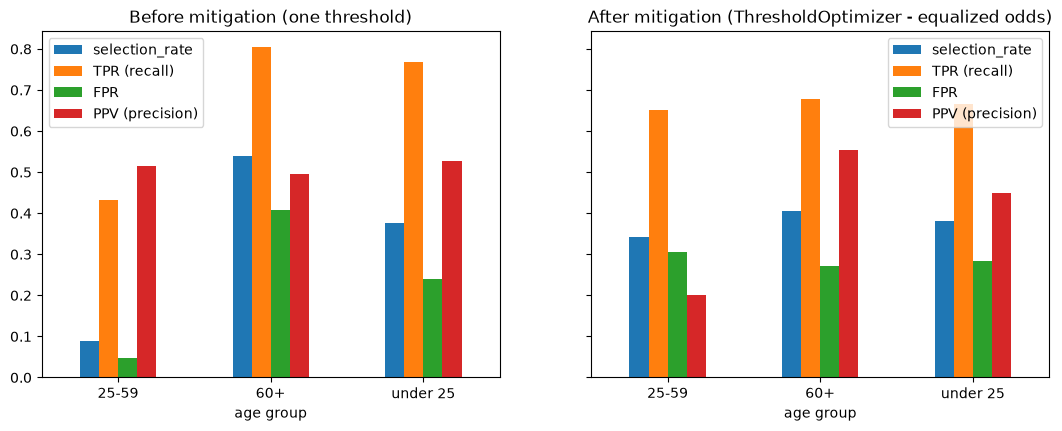

In [15]:
# ---------------- 4. plots ----------------
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
mf_before.by_group[["selection_rate", "TPR (recall)", "FPR", "PPV (precision)"]].plot(kind="bar", ax=axes[0])
axes[0].set_title("Before mitigation (one threshold)")
axes[0].set_xlabel("age group")
axes[0].tick_params(axis="x", rotation=0)
mf_after.by_group[["selection_rate", "TPR (recall)", "FPR", "PPV (precision)"]].plot(kind="bar", ax=axes[1])
axes[1].set_title("After mitigation (ThresholdOptimizer - equalized odds)")
axes[1].set_xlabel("age group")
axes[1].tick_params(axis="x", rotation=0)
plt.savefig("plots/fairness_by_age_group.png", dpi=150, bbox_inches="tight")
plt.show()

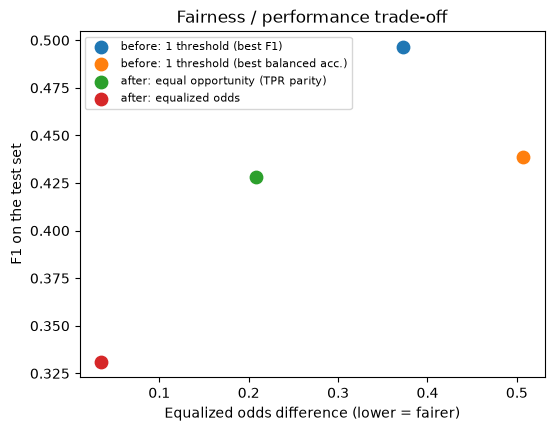


Saved plots/fairness_by_age_group.png and plots/fairness_tradeoff.png


In [16]:
plt.figure(figsize=(6, 4.5))
for i in range(len(compare_df)):
    plt.scatter(compare_df["eq. odds diff"][i], compare_df["f1"][i], s=80, label=compare_df["decision rule"][i])
plt.xlabel("Equalized odds difference (lower = fairer)")
plt.ylabel("F1 on the test set")
plt.title("Fairness / performance trade-off")
plt.legend(fontsize=8)
plt.savefig("plots/fairness_tradeoff.png", dpi=150, bbox_inches="tight")
plt.show()
print("\nSaved plots/fairness_by_age_group.png and plots/fairness_tradeoff.png")